# Figure 3

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_robustness_loo,
    load_ddm_subj_params,
    load_choicehistorypersubject_betas,
    load_rtlme_switchpersubject_betas,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pingouin as pg
import statsmodels.api as sm

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_DDM_MODEL = "HDDM_Base_Lag1-full"

RT_CORR_COLOR = "#4C72B0"

### Helper functions

In [2]:
BF_THRESHOLD_HIGH = 3
BF_THRESHOLD_LOW = 1 / 3

BF_COLORS = {
    "evidence_for":     "#2CA02C",
    "inconclusive":     "#B0B0B0",
    "evidence_against": "#6A51A3",
}


def bf_category(bf10):
    if bf10 > BF_THRESHOLD_HIGH:
        return "evidence_for"
    if bf10 < BF_THRESHOLD_LOW:
        return "evidence_against"
    return "inconclusive"


def format_bf(bf10):
    if bf10 >= 1000 or bf10 <= 0.001:
        return f"{bf10:.2e}"
    return f"{bf10:.2f}"


def pearson_corr_bf(x, y):
    """Pearson r/p plus the JZS Bayes Factor (BF10), and an OLS line + 95%
    CI band fit on every point (no outlier exclusion)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    res = pg.corr(x, y, method="pearson")
    r = float(res["r"].iloc[0])
    pval = float(res["p_val"].iloc[0])
    bf10 = float(res["BF10"].iloc[0])
    category = bf_category(bf10)

    ols_fit = sm.OLS(y, sm.add_constant(x)).fit()
    x_line = np.linspace(x.min(), x.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": r,
        "pval": pval,
        "bf10": bf10,
        "category": category,
        "n": len(x),
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }


def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    """Hide top/right spines; ylabel only in the first column (col == 0),
    xlabel only in xlabel_col (col == 1 by default). Pass col=None to just
    hide spines (e.g. row A, which has its own per-panel title)."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)


def plot_pearson_corr(ax, x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    result = pearson_corr_bf(x, y)
    color = BF_COLORS[result["category"]]

    ax.scatter(x, y, color=color, alpha=0.75, edgecolor="black",
               linewidth=0.5, s=40, zorder=3)
    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                     color=color, alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color=color, linewidth=1.5,
            linestyle="--", zorder=4)

    ax.text(0.05, 0.95,
            f"r = {result['r']:.2f}, p = {result['pval']:.3g}\n"
            f"BF10 = {format_bf(result['bf10'])}, n = {result['n']}",
            transform=ax.transAxes, ha="left", va="top", fontsize=9,
            color=color, fontweight="bold")

    return result


BF_LOG10_CAP = 5  # log10(BF10) = 5, i.e. BF10 = 1e5; finer resolution beyond
                  # this isn't meaningful (same rationale as the earlier
                  # -log10(p) cap in the previous version of this heatmap)

# Diverging colormap for the heatmap: evidence-against -> inconclusive ->
# evidence-for, using the same 3 anchor colors as the categorical BF_COLORS
# used for the scatterplot panels, so the two rows read consistently.
bf_diverging_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "bf_diverging",
    [BF_COLORS["evidence_against"], BF_COLORS["inconclusive"], BF_COLORS["evidence_for"]],
)
bf_diverging_norm = mpl.colors.Normalize(vmin=-BF_LOG10_CAP, vmax=BF_LOG10_CAP)


def compute_elpd_vs_baseline(dataset, baseline_model, model_order):
    """elpd_loo(variant) - elpd_loo(baseline_model) for each (model_id,
    label) in model_order. The two LOO comparison groups needed here share
    HDDM_Base's elpd_loo exactly (same model, same data), so concatenating
    and dropping the duplicate is safe."""
    loo_onemech = load_loo_comparison(dataset, group_name="choicehistory_onemechanism")
    loo_best = load_loo_comparison(dataset, group_name="choicehistory_bestmodel")
    loo = (pd.concat([loo_onemech, loo_best])
           .drop_duplicates(subset="model")
           .set_index("model")["elpd_loo"])
    baseline_elpd = loo[baseline_model]
    return [loo[m] - baseline_elpd for m, _ in model_order]


def compute_elpd_robustness_vs_baseline(dataset, baseline_model, model_order,
                                        column="elpd_loo_reliable_only"):
    """Robustness-check counterpart to compute_elpd_vs_baseline(), using the
    PSIS-LOO robustness files instead. The two comparison groups' baseline
    elpd are NOT merged/deduped here: Pareto-k reliability filtering is
    model-set dependent, so baseline_model's reliable-only elpd can differ
    slightly between groups -- each model is compared against its own
    group's own baseline row."""
    loo_onemech = load_robustness_loo(dataset, group_name="choicehistory_onemechanism").set_index("model")[column]
    loo_best = load_robustness_loo(dataset, group_name="choicehistory_bestmodel").set_index("model")[column]

    diffs = []
    for model_id, _ in model_order:
        loo = loo_onemech if model_id in loo_onemech.index else loo_best
        diffs.append(loo[model_id] - loo[baseline_model])
    return diffs


def elpd_vs_robustness_table(dataset, group_name):
    """elpd_loo (real) vs elpd_loo_reliable_only (robustness) for every
    model in one LOO comparison group."""
    real = load_loo_comparison(dataset, group_name=group_name).set_index("model")["elpd_loo"]
    robust = load_robustness_loo(dataset, group_name=group_name).set_index("model")["elpd_loo_reliable_only"]
    return pd.DataFrame({"elpd_loo": real, "elpd_loo_reliable_only": robust}).reset_index()


ELPD_THRESHOLD = 4

ELPD_COLORS = {
    "improved":  "#017D01",
    "ambiguous": "#8D8D8D",
    "worse":     "#980B0B",
}
ELPD_LABELS = {
    "improved":  "∆elpd > 4",
    "ambiguous": "otherwise",
    "worse":     "∆elpd < -4",
}


def elpd_category(diff):
    if diff > ELPD_THRESHOLD:
        return "improved"
    if diff < -ELPD_THRESHOLD:
        return "worse"
    return "ambiguous"


def plot_elpd_bars(ax, diffs, x_labels, col, show_legend=False):
    x_pos = np.arange(len(diffs))
    colors = [ELPD_COLORS[elpd_category(d)] for d in diffs]
    ax.bar(x_pos, diffs, color=colors, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(-8, 200)
    style_axis(ax, col, ylabel="Improvement over \nbaseline DDM (∆elpd-loo)",
              xlabel="DDM parameter(s) shifted by choice history")

    if show_legend:
        handles = [mpatches.Patch(facecolor=ELPD_COLORS[cat], label=ELPD_LABELS[cat])
                  for cat in ("improved", "worse", "ambiguous")]
        ax.legend(handles=handles, loc="upper left")


def compute_valuation_bias_diff(full_params):
    """Per-subject analog of the group-level lambda_accept - lambda_reject
    (Valuation Bias) used in the posterior-samples figure."""
    lambda_accept = ((full_params["v_loss_centered"] + full_params["v_loss_centered:choice_prev1"]) /
                      (full_params["v_gain_centered"] + full_params["v_gain_centered:choice_prev1"]))
    lambda_reject = ((full_params["v_loss_centered"] - full_params["v_loss_centered:choice_prev1"]) /
                      (full_params["v_gain_centered"] - full_params["v_gain_centered:choice_prev1"]))
    return lambda_accept - lambda_reject


def compute_heatmap_matrices(full_params, behavior_values, ddm_specs, behavior_specs):
    """r and clipped log10(BF10) matrices, one row per ddm_specs entry, one
    column per behavior_specs entry, from pairwise pearson_corr_bf()."""
    r_mat = np.full((len(ddm_specs), len(behavior_specs)), np.nan)
    log10_bf_mat = np.full((len(ddm_specs), len(behavior_specs)), np.nan)
    for i, (ddm_col, _) in enumerate(ddm_specs):
        for j, (beh_col, _) in enumerate(behavior_specs):
            merged = pd.concat(
                [full_params[ddm_col].rename("ddm"), behavior_values[beh_col].rename("beh")],
                axis=1, join="inner",
            ).dropna()
            result = pearson_corr_bf(merged["ddm"].values, merged["beh"].values)
            r_mat[i, j] = result["r"]
            log10_bf_mat[i, j] = np.clip(np.log10(result["bf10"]), -BF_LOG10_CAP, BF_LOG10_CAP)
    return r_mat, log10_bf_mat


def plot_bf_heatmap(ax, r_mat, log10_bf_mat, ddm_labels, beh_labels, cmap, norm, show_ylabels=True):
    ax.imshow(log10_bf_mat, cmap=cmap, norm=norm, aspect="auto")

    for i in range(r_mat.shape[0]):
        for j in range(r_mat.shape[1]):
            cell_rgba = cmap(norm(log10_bf_mat[i, j]))
            luminance = 0.299 * cell_rgba[0] + 0.587 * cell_rgba[1] + 0.114 * cell_rgba[2]
            text_color = "white" if luminance < 0.5 else "black"
            ax.text(j, i, f"r = {r_mat[i, j]:.2f}", ha="center", va="center",
                    color=text_color, fontsize=12, fontweight="bold")

    ax.set_xticks(range(len(beh_labels)))
    ax.set_xticklabels(beh_labels, fontsize=8)
    ax.set_yticks(range(len(ddm_labels)))
    ax.set_yticklabels(ddm_labels if show_ylabels else [], fontsize=8)

    ax.set_xticks(np.arange(-0.5, len(beh_labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(ddm_labels), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", bottom=False, left=False)
    for spine in ax.spines.values():
        spine.set_visible(False)

### 4x3 figure: 
1. LOO improvement
2. DDM-parameter x behavior heatmap
3. Correlation scatterplot
4. Correlation scatterplot

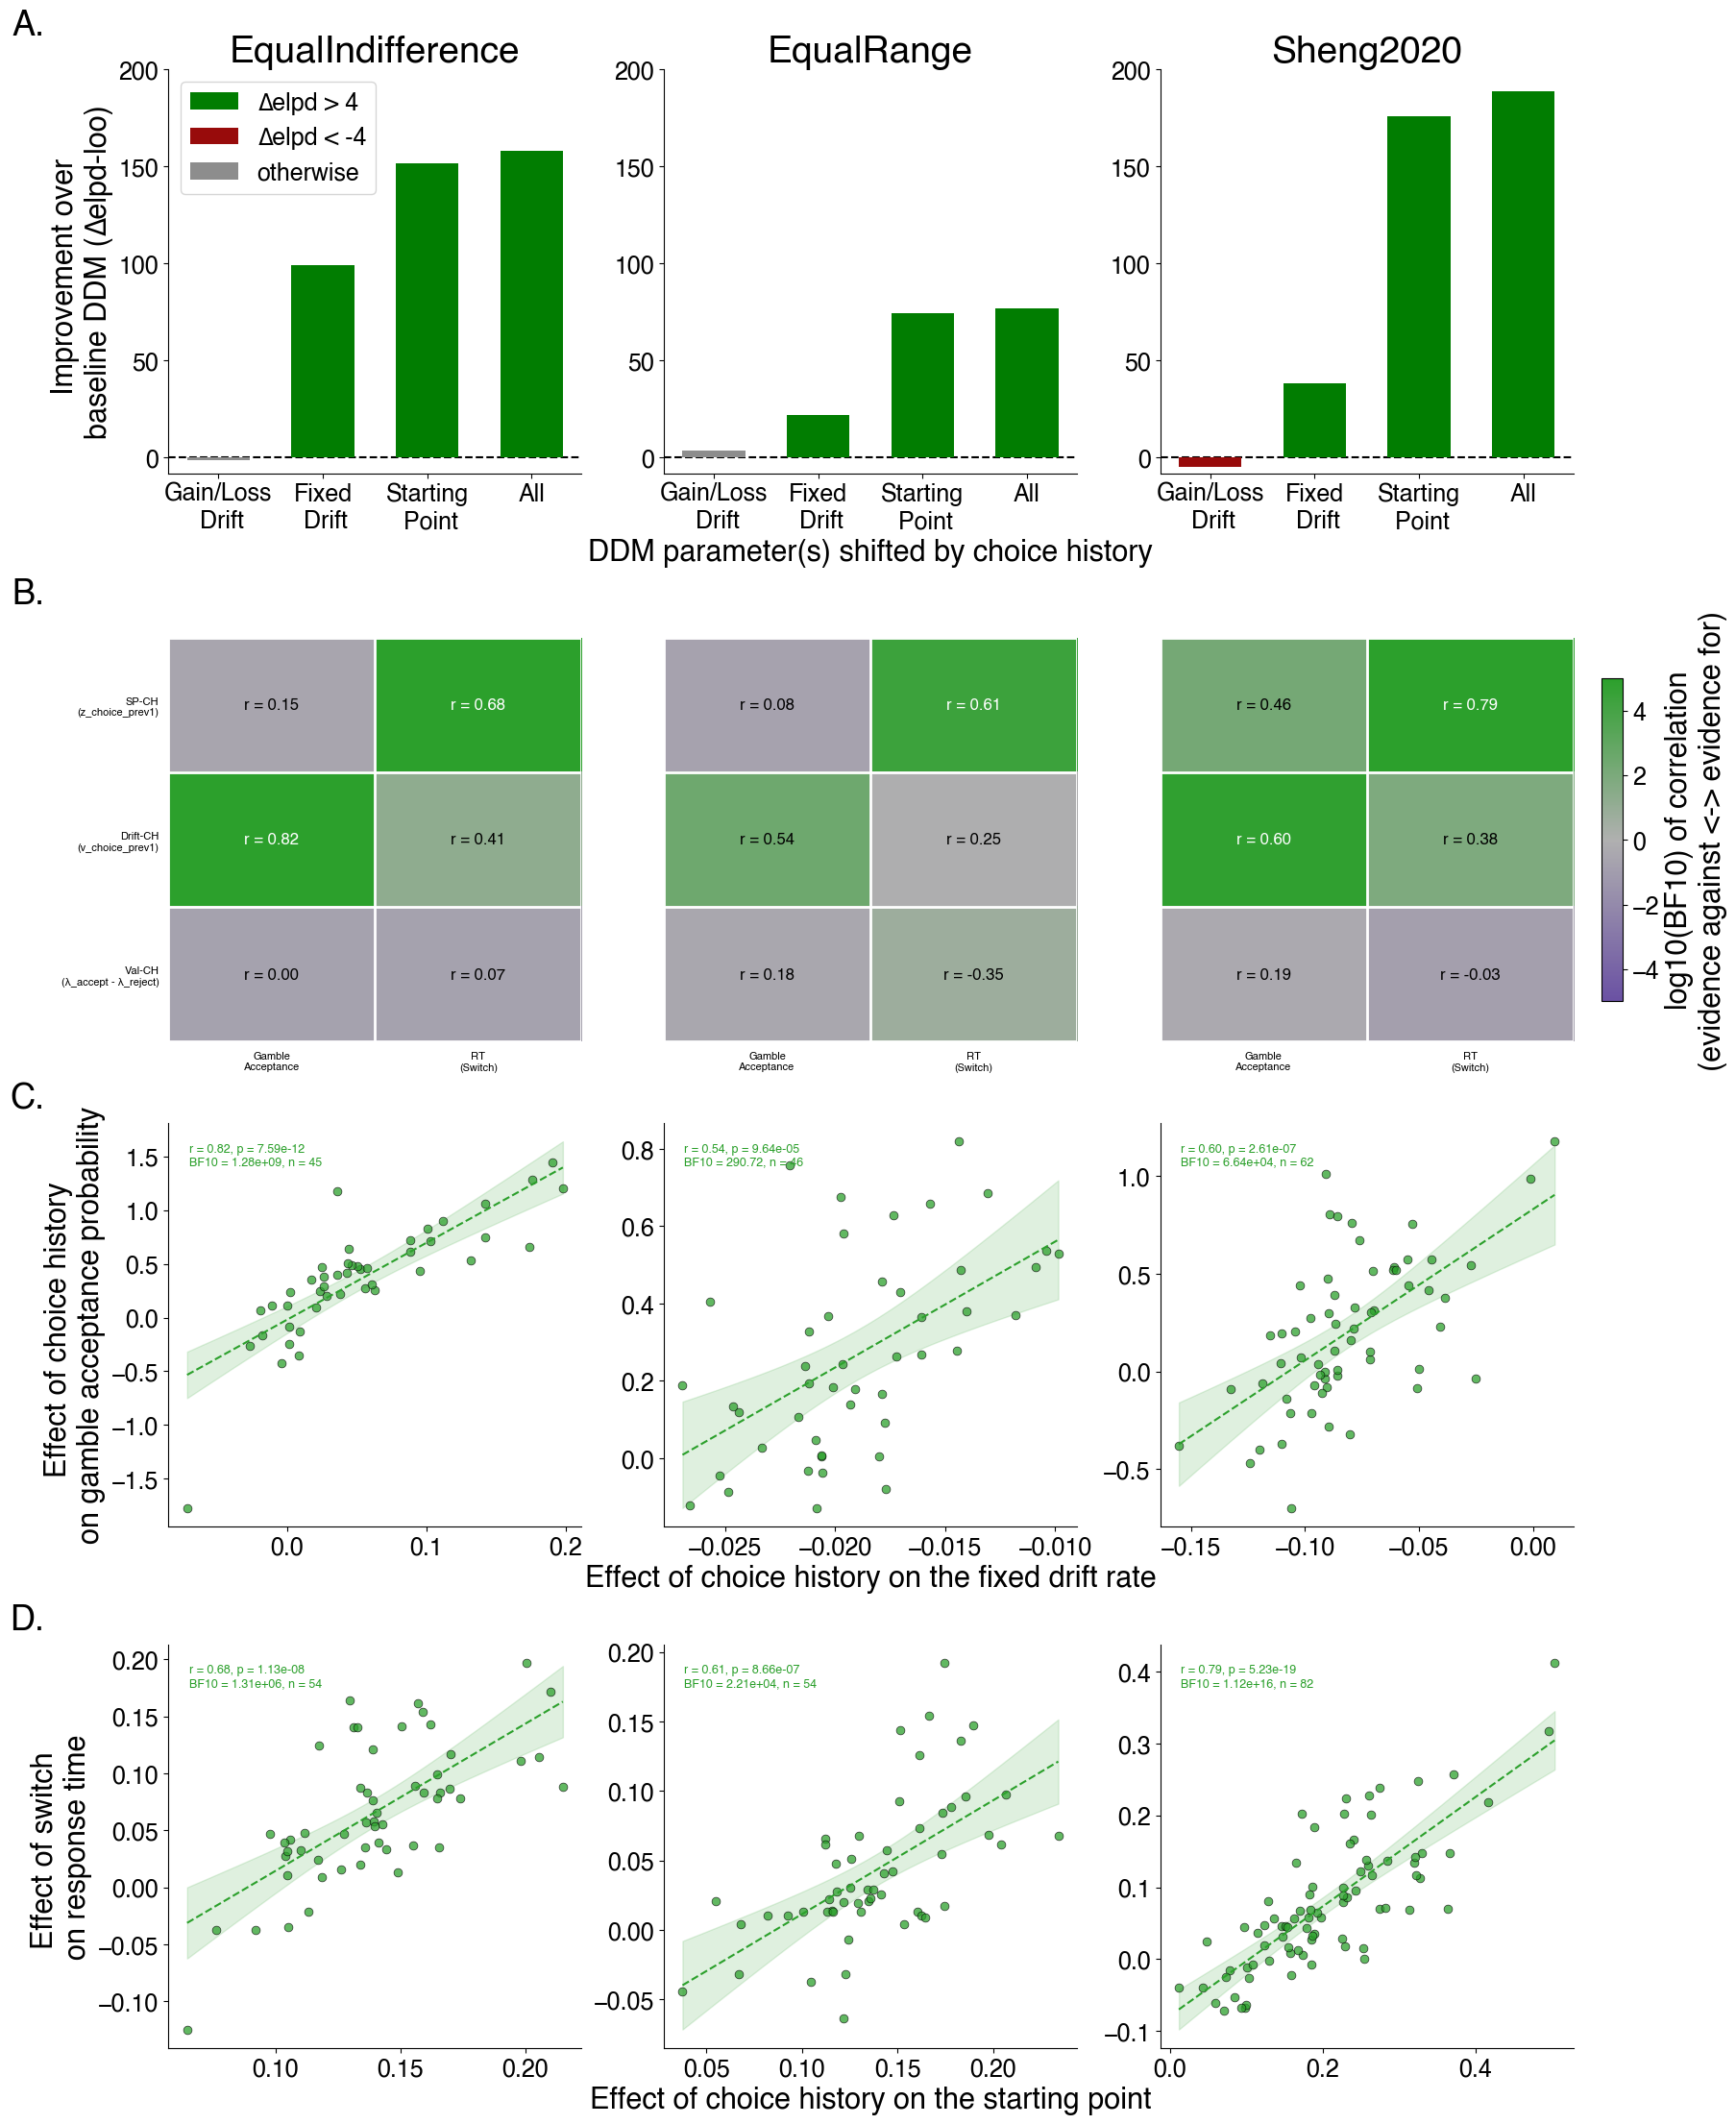

In [3]:
BASELINE_MODEL = "HDDM_Base"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stim",  "Gain/Loss\n Drift"),
    ("HDDM_Base_Lag1-drift", "Fixed\n Drift"),
    ("HDDM_Base_Lag1-stp",   "Starting\n Point"),
    ("HDDM_Base_Lag1-full",  "All"),
]
DDM_PARAM_SPECS = [
    ("z_choice_prev1", "SP-CH\n(z_choice_prev1)"),
    ("v_choice_prev1", "Drift-CH\n(v_choice_prev1)"),
]
BEHAVIOR_SPECS = [
    ("choice_prev1_effect", "Gamble\nAcceptance"),
    ("switch_effect", "RT\n(Switch)"),
]

choicehistory_betas = load_choicehistorypersubject_betas()
choicehistory_betas = choicehistory_betas[choicehistory_betas["converged"]]
switch_betas = load_rtlme_switchpersubject_betas()
switch_betas = switch_betas[switch_betas["converged"]]

elpd_vs_baseline = {}
drift_vs_choice = {}
z_vs_switch = {}
heatmap_data = {}

for ds in DATASETS:
    elpd_vs_baseline[ds] = compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER)

    full_params = (load_ddm_subj_params(FULL_DDM_MODEL, ds)
                   .pivot(index="sub", columns="param_name", values="param_value"))
    full_params["valuation_bias_diff"] = compute_valuation_bias_diff(full_params)

    beh_ds = (choicehistory_betas[choicehistory_betas["dataset"] == ds]
              .set_index("sub")["choice_prev1_effect"])
    switch_ds = (switch_betas[switch_betas["dataset"] == ds]
                 .set_index("sub")["switch_effect"])

    drift_vs_choice[ds] = pd.concat(
        [full_params["v_choice_prev1"].rename("v_choice_prev1"), beh_ds.rename("choice_prev1_effect")],
        axis=1, join="inner",
    )
    z_vs_switch[ds] = pd.concat(
        [full_params["z_choice_prev1"].rename("z_choice_prev1"), switch_ds.rename("switch_effect")],
        axis=1, join="inner",
    )

    ddm_specs = DDM_PARAM_SPECS + [("valuation_bias_diff", "Val-CH\n(λ_accept - λ_reject)")]
    behavior_values = {"choice_prev1_effect": beh_ds, "switch_effect": switch_ds}
    r_mat, log10_bf_mat = compute_heatmap_matrices(full_params, behavior_values, ddm_specs, BEHAVIOR_SPECS)
    heatmap_data[ds] = {"r": r_mat, "log10_bf": log10_bf_mat, "ddm_labels": [lbl for _, lbl in ddm_specs]}

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 22), layout="constrained")
beh_labels = [lbl for _, lbl in BEHAVIOR_SPECS]
elpd_labels = [label for _, label in ELPD_MODEL_ORDER]

for col, ds in enumerate(DATASETS):
    plot_elpd_bars(axes[0, col], elpd_vs_baseline[ds], elpd_labels, col, show_legend=(col == 0))
    axes[0, col].set_title(DATASET_LABELS.get(ds, ds))

    plot_bf_heatmap(axes[1, col], heatmap_data[ds]["r"], heatmap_data[ds]["log10_bf"],
                    heatmap_data[ds]["ddm_labels"], beh_labels,
                    bf_diverging_cmap, bf_diverging_norm, show_ylabels=(col == 0))

    merged = drift_vs_choice[ds]
    plot_pearson_corr(axes[2, col], merged["v_choice_prev1"].values, merged["choice_prev1_effect"].values)
    style_axis(axes[2, col], col,
              ylabel="Effect of choice history \non gamble acceptance probability",
              xlabel="Effect of choice history on the fixed drift rate")

    merged = z_vs_switch[ds]
    plot_pearson_corr(axes[3, col], merged["z_choice_prev1"].values, merged["switch_effect"].values)
    style_axis(axes[3, col], col,
              ylabel="Effect of switch \non response time",
              xlabel="Effect of choice history on the starting point")

bf_colorbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=bf_diverging_norm, cmap=bf_diverging_cmap),
    ax=axes[1, :], shrink=0.8, pad=0.02, aspect=15,
)
bf_colorbar.set_label("log10(BF10) of correlation\n(evidence against <-> evidence for)")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
for row, label in enumerate(["A.", "B.", "C.", "D."]):
    y = 1.15 if row < 2 else 1.1
    axes[row, 0].text(-0.3, y, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure3.svg", dpi=300, bbox_inches="tight")
plt.show()

### Robustness check
Per dataset: ∆elpd (baseline vs. model, from Row A) next to the PSIS-LOO robustness-check ∆elpd (same comparison restricted to observations with reliable Pareto-k, `elpd_loo_reliable_only`).

In [4]:
for ds in DATASETS:
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER)
    summary = pd.DataFrame({
        "model": elpd_labels,
        "delta_elpd": elpd_vs_baseline[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
            model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift   -1.476759          -3.217254
    Fixed\n Drift   99.352246          99.688030
 Starting\n Point  151.692313         122.166458
              All  158.072678         134.967534

equalRange
            model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift    3.878474           3.597005
    Fixed\n Drift   21.858156          20.931258
 Starting\n Point   74.481972          58.135792
              All   76.716253          58.424649

sheng2020
            model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift   -4.523189          -3.460168
    Fixed\n Drift   38.324040          41.115932
 Starting\n Point  176.002296         152.369425
              All  188.597556         157.022972


### Best-model comparison: real vs. robustness elpd
Per dataset, elpd_loo vs. elpd_loo_reliable_only for every model in the `choicehistory_bestmodel` comparison group.

In [5]:
for ds in DATASETS:
    print(f"\n{ds}")
    print(elpd_vs_robustness_table(ds, "choicehistory_bestmodel").to_string(index=False))


equalIndifference
                  model      elpd_loo  elpd_loo_reliable_only
HDDM_Base_Lag1-stpdrift -11741.138401           -11474.152040
    HDDM_Base_Lag1-full -11745.420216           -11477.253141
              HDDM_Base -11903.492894           -11612.220675

equalRange
                  model      elpd_loo  elpd_loo_reliable_only
HDDM_Base_Lag1-stpdrift -11224.777355           -10908.462748
    HDDM_Base_Lag1-full -11226.409932           -10910.854087
              HDDM_Base -11303.126185           -10969.278736

sheng2020
                  model     elpd_loo  elpd_loo_reliable_only
HDDM_Base_Lag1-stpdrift -9137.921520            -8861.415272
    HDDM_Base_Lag1-full -9139.658710            -8863.739187
              HDDM_Base -9328.256266            -9020.762159
